<a href="https://colab.research.google.com/github/dherreraal/data_structures/blob/main/Clase_11/11_ED_AVL_Insert_Rotate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Árboles AVL: Inserción y Rotaciones (AVL Trees: Insert & Rotate)
### Universidad Nacional de Colombia
#### **Profesor:** David Alberto Herrera Alvarez
#### **Curso:** Estructuras de Datos
---


## Índice de Contenido
1. Introducción y Motivación: El Problema del Desbalanceo en Árboles Binarios de Búsqueda
2. Medición del Balance: Concepto de Altura y la Propiedad AVL
3. Análisis Matemático de Daniel Kane: Por qué la Propiedad AVL Garantiza $O(\log n)$
4. Rebalanceo y Rotaciones: Preservando el Invariante de Búsqueda ($A < Y < B < X < C$)
   - 4.1 Rotación Simple a la Derecha (`RotateRight`)
   - 4.2 Rotación Simple a la Izquierda (`RotateLeft`)
   - 4.3 Demostración Interactiva en Java: Rotaciones Simples
5. Los Cuatro Casos de Desbalanceo y Rotaciones Dobles
   - 5.1 Caso Exterior Izquierdo (Left-Left, LL)
   - 5.2 Caso Exterior Derecho (Right-Right, RR)
   - 5.3 Caso Interior Izquierdo (Left-Right, LR): El Caso Crítico "Zigzag"
   - 5.4 Caso Interior Derecho (Right-Left, RL): El Caso Espejo "Zagzig"
   - 5.5 Demostración Interactiva en Java: Rotaciones Dobles
6. Algoritmo Completo de Inserción en Árboles AVL (`AVLInsert`)
   - 6.1 Mecanismo de Inserción y Propagación de Alturas en el Camino
   - 6.2 Pseudocódigo Formal de Daniel Kane (`Rebalance`, `AdjustHeight`, `RebalanceRight`)
   - 6.3 Implementación Completa y Ejecutable de un Árbol AVL en Java
7. Resolución Pedagógica del Problema de Daniel Kane
8. Análisis Comparativo de Rendimiento (BST Degenerado vs. Árbol AVL)
9. Ejercicios Prácticos
   - Ejercicio 1: Implementación de Rotaciones Simples (`RotacionesSimples.java`)
   - Ejercicio 2: Implementación de Rotaciones Dobles LR y RL (`RotacionesDobles.java`)
   - Ejercicio 3: Inserción Completa en un Árbol AVL (`AVLInsertEjercicio.java`)
   - Ejercicio 4: Instrumentación y Conteo de Rotaciones (`ConteoRotacionesAVL.java`)
   - Ejercicio 5: Aplicación Práctica: Diccionario Simbólico Balanceado (`DiccionarioAVL.java`)
10. Bibliografía y Referencias


## 1. Introducción y Motivación: El Problema del Desbalanceo en BST

En las sesiones previas construimos el **Árbol Binario de Búsqueda (BST)** y demostramos que sus operaciones fundamentales (búsqueda `find`, inserción `insert` y eliminación `delete`) tienen una complejidad temporal que depende directamente de la **profundidad** o altura del árbol:

$$\text{Tiempo de Operación} = O(\text{Depth}) = O(h)$$

Donde $h$ representa la longitud del camino más largo desde la raíz hasta una hoja.

### El Dilema del BST Estándar
Cuando insertamos claves en un orden aleatorio o bien distribuido, el árbol binario tiende a crecer de forma armónica a izquierda y derecha, manteniendo una altura $h \approx O(\log n)$. En este escenario ideal, buscar un elemento entre un millón de registros toma tan solo unas 20 comparaciones.

Sin embargo, el BST estándar es **pasivo**: no toma ninguna medida activa para mantener su forma. Si las claves se insertan en un orden desfavorable (por ejemplo, en orden estrictamente ascendente como `[1, 2, 3, 4, 5, 6, 7]` o descendente `[7, 6, 5, 4, 3, 2, 1]`), cada nuevo nodo se ubica sistemáticamente como hijo derecho (o izquierdo) del nodo anterior.

El resultado es un **BST degenerado**:
* La estructura se colapsa visual y funcionalmente en una **lista enlazada simple**.
* La altura del árbol alcanza el peor caso absoluto: $h = n$.
* El tiempo de búsqueda se degrada dramáticamente de $O(\log n)$ a **$O(n)$**.

<div align="center">
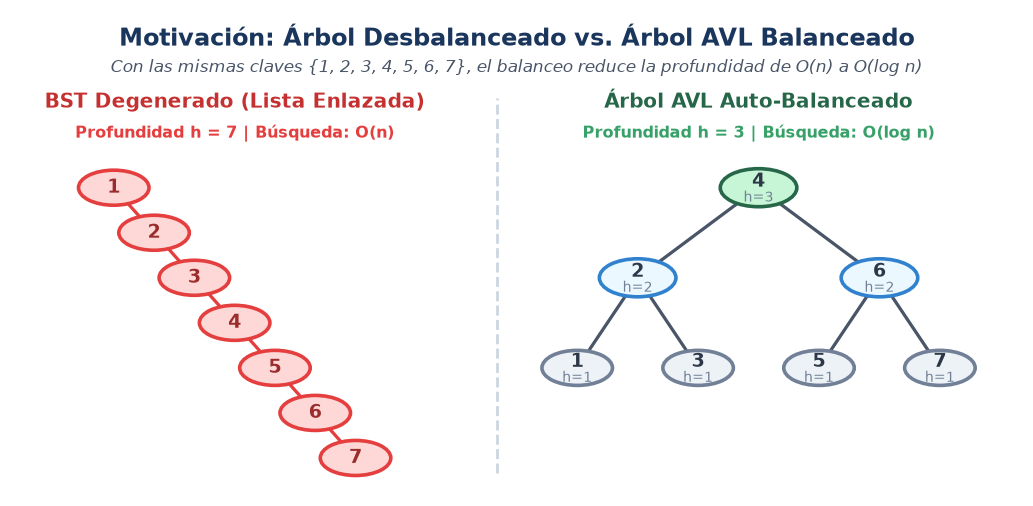
</div>

### La Solución: Árboles Auto-Balanceados (AVL)
Para evitar que un BST degenere en una lista lineal, en 1962 los matemáticos soviéticos **Georgy Adelson-Velsky** y **Evgenii Landis** propusieron la primera estructura de árbol binario de búsqueda auto-balanceado de la historia de la computación: el **Árbol AVL**.

La idea rectora de Adelson-Velsky y Landis es sumamente elegante:
1. Definir una métrica geométrica precisa de "equilibrio" local en cada nodo: la **altura**.
2. Exigir que en **todo momento** los subárboles izquierdo y derecho de cualquier nodo tengan alturas casi idénticas (con una diferencia máxima de 1 nivel).
3. Monitorear las inserciones; en cuanto una inserción altere esta condición en algún nodo ancestro, reestructurar inmediatamente el árbol de forma local mediante **rotaciones** en tiempo $O(1)$, restaurando la propiedad sin violar jamás el orden de búsqueda BST.


## 2. Medición del Balance: Concepto de Altura y la Propiedad AVL

Para poder corregir un desbalance, primero debemos ser capaces de cuantificarlo formalmente en cada nodo de la estructura.

### 2.1 Definición Formal de Altura
Siguiendo la convención pedagógica rigurosa adoptada por Daniel Kane (UCSD):

> **Definición (Altura de un Nodo):**
> La **altura** de un nodo $N$, denotada como $N.\text{Height}$ (o $h(N)$), es la máxima profundidad de su subárbol.
>
> Recursivamente se define como:
> $$N.\text{Height} = \begin{cases}
> 0 & \text{si } N \text{ es } \text{null} \\
> 1 & \text{si } N \text{ es una hoja (sin hijos)} \\
> 1 + \max(N.\text{Left}.\text{Height},\; N.\text{Right}.\text{Height}) & \text{en cualquier otro caso}
> \end{cases}$$

*(Nota técnica: Algunas fuentes en la literatura definen la altura de una hoja como 0 y la de un puntero nulo como -1. La convención de Kane asigna 1 a la hoja y 0 a null. Ambas son matemáticamente equivalentes al calcular diferencias de altura).*

### 2.2 Campo de Altura en el Nodo (`Node.height`)
Calcular la altura recorriendo todo el subárbol cada vez que deseamos verificar el balance tomaría $O(k)$ pasos (donde $k$ es el tamaño del subárbol), lo cual arruinaría la eficiencia del algoritmo. Por ello, en un Árbol AVL **cada nodo almacena explícitamente su propia altura** como un atributo entero en memoria:

```java
class Node {
    int key;
    int height; // Altura mantenida y actualizada en O(1)
    Node left;
    Node right;
    
    public Node(int key) {
        this.key = key;
        this.height = 1; // Un nuevo nodo hoja nace con altura 1
    }
}
```

### 2.3 Factor de Balance (Balance Factor - BF)
El **Factor de Balance** de un nodo $N$, denotado como $BF(N)$, es la diferencia entre la altura de su subárbol izquierdo y la de su subárbol derecho:

$$BF(N) = N.\text{Left}.\text{Height} - N.\text{Right}.\text{Height}$$

### 2.4 La Propiedad AVL (AVL Property)
> **Definición (Propiedad AVL):**
> Un árbol binario de búsqueda satisface la **Propiedad AVL** si y solo si, para **todo** nodo $N$ del árbol:
>
> $$|N.\text{Left}.\text{Height} - N.\text{Right}.\text{Height}| \le 1$$
>
> Es decir, los únicos valores de Factor de Balance permitidos en cualquier nodo son:
> $$BF(N) \in \{-1,\; 0,\; +1\}$$

* Si $BF(N) = 0$: Los subárboles izquierdo y derecho tienen exactamente la misma altura (equilibrio perfecto).
* Si $BF(N) = +1$: El subárbol izquierdo es un nivel más alto que el derecho (árbol izquierdo-pesado, pero válido).
* Si $BF(N) = -1$: El subárbol derecho es un nivel más alto que el izquierdo (árbol derecho-pesado, pero válido).
* Si $|BF(N)| \ge 2$: **¡Violación de la propiedad AVL!** El nodo $N$ está desbalanceado y requiere intervención inmediata mediante una rotación.

<div align="center">
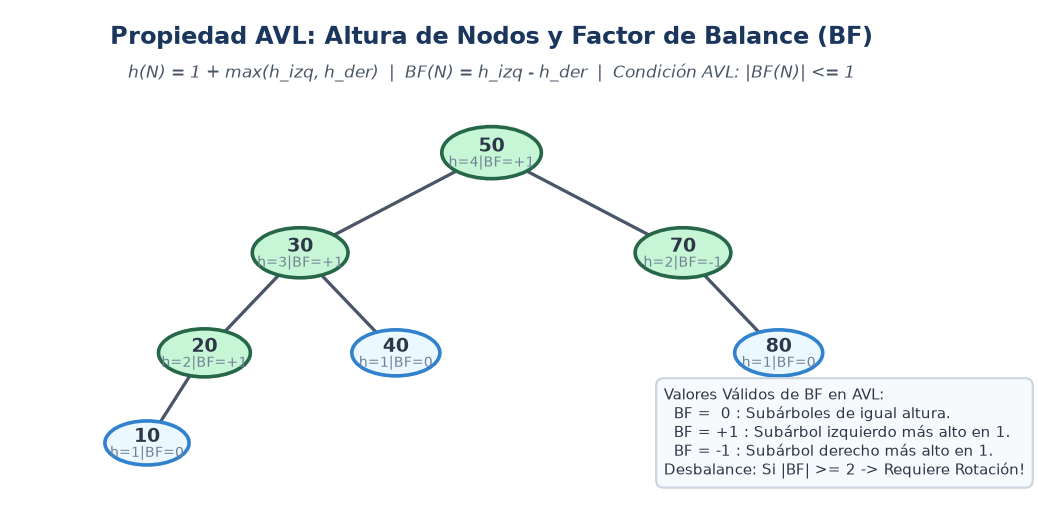
</div>


## 3. Análisis Matemático de Daniel Kane: Por qué la Propiedad AVL Garantiza $O(\log n)$

Una pregunta teórica fundamental que cualquier estudiante de ciencias de la computación debe hacerse es: **¿Es suficiente exigir que la diferencia de alturas sea a lo sumo 1 para garantizar que la altura global del árbol sea logarítmica respecto al número total de nodos $n$?**

¿Podría ocurrir que, encadenando pequeñas diferencias de altura de nivel en nivel, el árbol creciera hasta tener una altura lineal o polinomial?

La respuesta es un rotundo **NO**, y la demostración formal presentada por Daniel Kane (UCSD) utilizando los **Números de Fibonacci** es una de las joyas de la teoría de estructuras de datos.

### 3.1 La Estrategia de la Demostración
Para demostrar que la altura $h$ es $O(\log n)$, podemos demostrar el enunciado recíproco y equivalente:
$$\text{Un árbol AVL de altura } h \text{ debe contener una cantidad exponencial de nodos } n.$$

Si construimos el árbol AVL más "delgado" o con la menor cantidad de nodos posible para una altura dada $h$, ¿cuántos nodos debe tener como mínimo?

### 3.2 Repaso: Sucesión de Fibonacci
Recordemos la definición clásica de la sucesión de Fibonacci:
$$F_0 = 0, \quad F_1 = 1, \quad F_2 = 1, \quad F_3 = 2, \quad F_4 = 3, \quad F_5 = 5, \quad F_6 = 8, \dots$$
$$F_n = F_{n-1} + F_{n-2} \quad \text{para } n > 1$$

Una propiedad fundamental de esta sucesión es que crece exponencialmente:
$$F_n \ge 2^{n/2} \quad \text{para todo } n \ge 6$$

### 3.3 Teorema y Demostración por Inducción (Kane Slide 16-21)
> **Teorema de la Cota Inferior de Nodos en Árboles AVL:**
> Sea $N$ un nodo de un árbol binario que satisface la propiedad AVL, y sea $h = N.\text{Height}$ su altura. Entonces, el subárbol con raíz en $N$ contiene **al menos** $F_h$ nodos (el $h$-ésimo número de Fibonacci).

**Demostración (Por inducción matemática sobre $h$):**

* **Caso Base ($h = 1$):**
  Un nodo con altura $h = 1$ es una hoja solitaria. Contiene exactamente 1 nodo.
  Como $F_1 = 1$, se cumple trivialmente: $1 \ge F_1$.

* **Paso Inductivo:**
  Asumamos como Hipótesis de Inducción que para cualquier nodo de altura menor que $h$, el tamaño de su subárbol es al menos $F_{\text{altura}}$.
  
  Consideremos ahora un nodo $N$ de altura $h > 1$. Para que $N$ tenga altura $h$, al menos uno de sus hijos debe tener altura $h - 1$.
  
  Por la propiedad AVL, la altura del otro hijo no puede diferir en más de 1 unidad de la del primer hijo. Por lo tanto, el otro hijo debe tener una altura de **al menos $h - 2$**.
  
  Aplicando la hipótesis inductiva a ambos subárboles hijos:
  $$\text{Nodos en el subárbol izquierdo} \ge F_{h-1}$$
  $$\text{Nodos en el subárbol derecho} \ge F_{h-2}$$
  
  El total de nodos en el subárbol con raíz en $N$ es:
  $$\text{Total Nodos}(N) = 1 + \text{Nodos}(\text{izq}) + \text{Nodos}(\text{der})$$
  $$\text{Total Nodos}(N) \ge 1 + F_{h-1} + F_{h-2} > F_{h-1} + F_{h-2} = F_h$$
  
  Por el principio de inducción matemática, el teorema queda demostrado para todo $h \ge 1$. $\blacksquare$

### 3.4 Consecuencia: Cota Superior de la Altura
Dado que un árbol con $n$ nodos y altura $h$ cumple que $n \ge F_h$, y sabemos que $F_h \ge 2^{h/2}$:

$$n \ge 2^{h/2}$$

Aplicando logaritmo en base 2 a ambos lados:
$$\log_2(n) \ge \frac{h}{2} \implies h \le 2 \log_2(n)$$

$$h = O(\log n)$$

*(Un análisis más fino utilizando la proporción áurea $\phi = \frac{1+\sqrt{5}}{2} \approx 1.618$ demuestra que $h \le 1.44 \log_2(n)$).*

**Conclusión:**
¡La propiedad AVL garantiza matemáticamente que la altura del árbol nunca superará una cota logarítmica respecto a $n$! Por lo tanto, **todas las operaciones de búsqueda, inserción y recorrido en un árbol AVL tienen un costo garantizado de $O(\log n)$ en el peor caso posible.**


## 4. Rebalanceo y Rotaciones: Preservando el Invariante de Búsqueda

Cuando una inserción rompe la propiedad AVL (generando un factor de balance de $+2$ o $-2$), debemos reestructurar el árbol para reducir su altura. Pero enfrentamos una restricción crítica:

> **El Principio Sagrado del Rebalanceo:**
> La reestructuración del árbol debe modificar las alturas pero **NO PUEDE alterar bajo ninguna circunstancia el orden simétrico (in-orden) de las claves**.

La herramienta fundamental para lograr esto es la **rotación de nodos**.

### 4.1 Invariante de Orden BST en una Rotación
Consideremos dos nodos $X$ e $Y$, y tres subárboles $A$, $B$ y $C$. En un BST, una configuración donde $Y$ es hijo izquierdo de $X$ implica la siguiente relación de orden estricto de izquierda a derecha:

$$A < Y < B < X < C$$

Observemos con detenimiento:
* Todo elemento en el subárbol $A$ es menor que $Y$.
* Todo elemento en el subárbol $B$ es mayor que $Y$, pero menor que $X$.
* Todo elemento en el subárbol $C$ es mayor que $X$.

Una **rotación a la derecha** eleva al nodo $Y$ a la posición de raíz y desciende a $X$ para convertirse en su hijo derecho. Para mantener el invariante, el subárbol central $B$ (cuyos valores están entre $Y$ y $X$) pasa a ser el nuevo hijo izquierdo de $X$.

Si leemos el árbol resultante en in-orden:
$$(A) \rightarrow Y \rightarrow (B) \rightarrow X \rightarrow (C)$$
¡El orden de las claves es exactamente el mismo! No se perdió ni desordenó un solo dato.

<div align="center">
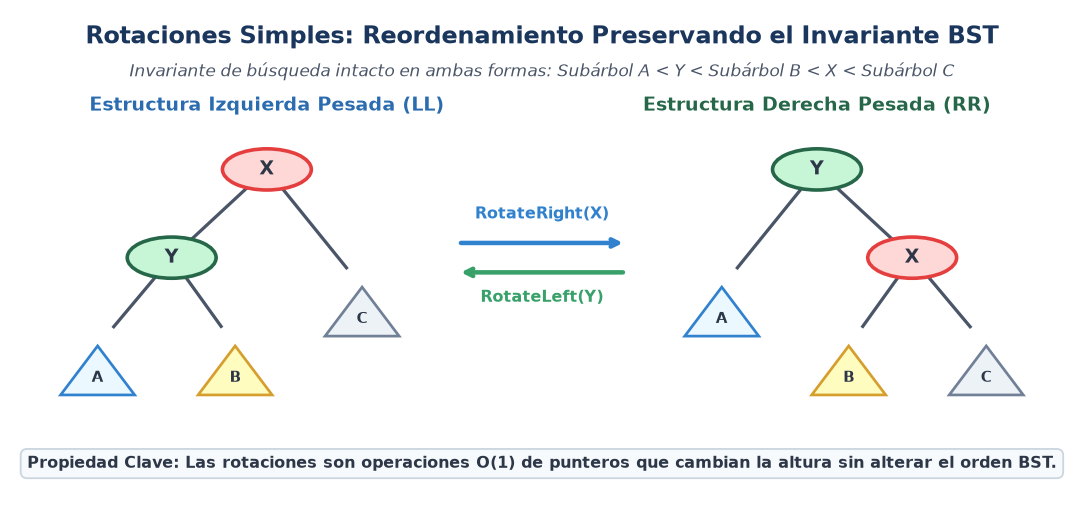
</div>

### 4.2 Algoritmo de Rotación Simple a la Derecha (`RotateRight`)
A continuación se presenta la implementación formal de `RotateRight(X)` descrita por Daniel Kane.

En árboles con puntero al padre (`Parent`):
```text
RotateRight(X):
    P <- X.Parent
    Y <- X.Left
    B <- Y.Right
    Y.Parent <- P
    P.AppropriateChild <- Y
    X.Parent <- Y
    Y.Right <- X
    B.Parent <- X
    X.Left <- B
```

En la práctica estándar de Java orientada a objetos (especialmente con métodos recursivos que retornan la nueva raíz del subárbol), el algoritmo se simplifica notablemente:

```java
// Rotación simple a la derecha con pivote en y
static Node rotateRight(Node y) {
    Node x = y.left;      // x pasa a ser la nueva raíz del subárbol
    Node T2 = x.right;    // T2 es el subárbol central B

    // Reasignación de referencias
    x.right = y;          // y pasa a ser hijo derecho de x
    y.left = T2;          // T2 pasa a ser hijo izquierdo de y

    // Actualización de alturas (primero el nodo que quedó abajo)
    updateHeight(y);
    updateHeight(x);

    return x;             // Retornamos la nueva raíz
}
```

### 4.3 Algoritmo de Rotación Simple a la Izquierda (`RotateLeft`)
La **rotación a la izquierda** es la operación exactamente simétrica a la rotación a la derecha. Se aplica cuando el subárbol derecho de un nodo $X$ es demasiado pesado (factor de balance $-2$):

```java
// Rotación simple a la izquierda con pivote en x
static Node rotateLeft(Node x) {
    Node y = x.right;     // y pasa a ser la nueva raíz del subárbol
    Node T2 = y.left;     // T2 es el subárbol central B

    // Reasignación de referencias
    y.left = x;           // x pasa a ser hijo izquierdo de y
    x.right = T2;         // T2 pasa a ser hijo derecho de x

    // Actualización de alturas (primero el nodo inferior)
    updateHeight(x);
    updateHeight(y);

    return y;             // Retornamos la nueva raíz
}
```

### Propiedades Clave de las Rotaciones:
1. **Complejidad Temporal $O(1)$:** Solo involucran reasignar 3 o 4 punteros en memoria y calcular dos sumas para las alturas.
2. **Preservación In-Orden:** El recorrido in-orden antes y después de la rotación es idéntico.
3. **Reducción de Altura:** Disminuyen en 1 la altura del camino desbalanceado, restaurando el balance local.


### 4.3 Demostración Interactiva en Java: Rotaciones Simples en Acción

A continuación ejecutaremos un programa completo en Java que construye dos árboles desbalanceados paso a paso (uno con desbalance a la izquierda y otro a la derecha), muestra su estructura gráfica en consola con sus factores de balance, y aplica `rotateRight` y `rotateLeft` para demostrar la restauración instantánea del equilibrio.


In [1]:
%%writefile DemostracionRotacionesSimples.java
public class DemostracionRotacionesSimples {

    static class Node {
        int key;
        int height;
        Node left, right;

        public Node(int key) {
            this.key = key;
            this.height = 1;
        }
    }

    static int height(Node n) {
        return (n == null) ? 0 : n.height;
    }

    static int getBalanceFactor(Node n) {
        return (n == null) ? 0 : height(n.left) - height(n.right);
    }

    static void updateHeight(Node n) {
        if (n != null) {
            n.height = 1 + Math.max(height(n.left), height(n.right));
        }
    }

    static Node rotateRight(Node y) {
        System.out.println(">>> Ejecutando RotateRight en nodo con clave: " + y.key);
        Node x = y.left;
        Node T2 = x.right;

        x.right = y;
        y.left = T2;

        updateHeight(y);
        updateHeight(x);

        return x;
    }

    static Node rotateLeft(Node x) {
        System.out.println(">>> Ejecutando RotateLeft en nodo con clave: " + x.key);
        Node y = x.right;
        Node T2 = y.left;

        y.left = x;
        x.right = T2;

        updateHeight(x);
        updateHeight(y);

        return y;
    }

    static void printTree(Node node, String prefix, boolean isLeft) {
        if (node != null) {
            System.out.println(prefix + (isLeft ? "|-- (L) " : "\\-- (R) ")
                               + node.key + " [h=" + node.height + ", BF=" + getBalanceFactor(node) + "]");
            printTree(node.left, prefix + (isLeft ? "|   " : "    "), true);
            printTree(node.right, prefix + (isLeft ? "|   " : "    "), false);
        }
    }

    static void inOrder(Node n) {
        if (n != null) {
            inOrder(n.left);
            System.out.print(n.key + " ");
            inOrder(n.right);
        }
    }

    public static void main(String[] args) {
        System.out.println("======================================================================");
        System.out.println("DEMOSTRACION 1: Rotacion Simple a la Derecha (Caso Left-Left - LL)");
        System.out.println("======================================================================");
        Node rootLL = new Node(30);
        rootLL.left = new Node(20);
        rootLL.left.left = new Node(10);
        updateHeight(rootLL.left);
        updateHeight(rootLL);

        System.out.println("Arbol antes de rotar (Observe el BF = +2 en la raiz 30):");
        printTree(rootLL, "", false);
        System.out.print("Recorrido In-Orden antes: ");
        inOrder(rootLL);
        System.out.println();

        rootLL = rotateRight(rootLL);

        System.out.println();
        System.out.println("Arbol despues de RotateRight(30) (Balance restaurado, BF en [-1, 1]):");
        printTree(rootLL, "", false);
        System.out.print("Recorrido In-Orden despues: ");
        inOrder(rootLL);
        System.out.println();
        System.out.println("(El orden simetrico se mantuvo intacto: 10, 20, 30!)");

        System.out.println();
        System.out.println("======================================================================");
        System.out.println("DEMOSTRACION 2: Rotacion Simple a la Izquierda (Caso Right-Right - RR)");
        System.out.println("======================================================================");
        Node rootRR = new Node(10);
        rootRR.right = new Node(20);
        rootRR.right.right = new Node(30);
        updateHeight(rootRR.right);
        updateHeight(rootRR);

        System.out.println("Arbol antes de rotar (Observe el BF = -2 en la raiz 10):");
        printTree(rootRR, "", false);
        System.out.print("Recorrido In-Orden antes: ");
        inOrder(rootRR);
        System.out.println();

        rootRR = rotateLeft(rootRR);

        System.out.println();
        System.out.println("Arbol despues de RotateLeft(10) (Balance restaurado, BF en [-1, 1]):");
        printTree(rootRR, "", false);
        System.out.print("Recorrido In-Orden despues: ");
        inOrder(rootRR);
        System.out.println();
        System.out.println("(El orden simetrico se mantuvo intacto: 10, 20, 30!)");
    }
}


Writing DemostracionRotacionesSimples.java


In [2]:
!javac -encoding UTF-8 DemostracionRotacionesSimples.java
!java DemostracionRotacionesSimples


[0.021s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.021s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACION 1: Rotacion Simple a la Derecha (Caso Left-Left - LL)
Arbol antes de rotar (Observe el BF = +2 en la raiz 30):
\-- (R) 30 [h=3, BF=2]
    |-- (L) 20 [h=2, BF=1]
    |   |-- (L) 10 [h=1, BF=0]
Recorrido In-Orden antes: 10 20 30 
>>> Ejecutando RotateRight en nodo con clave: 30

Arbol despues de RotateRight(30) (Balance restaurad

## 5. Los Cuatro Casos de Desbalanceo y Rotaciones Dobles

Al insertar un nuevo nodo en un Árbol AVL, el desbalanceo ocurre porque la altura de uno de los subárboles creció más de lo permitido. Analizando la trayectoria de los últimos dos enlaces recorridos desde el ancestro desbalanceado $N$ hacia el nodo recién insertado, se presentan **exactamente cuatro casos posibles**:

| Caso | Denominación | Significado | Condición de BF | Solución Requerida |
| :---: | :---: | :---: | :---: | :---: |
| **1** | **Exterior Izquierdo (LL)** | Inserción en subárbol izquierdo del hijo izquierdo | $BF(N) = +2$ y $BF(N.\text{left}) \ge 0$ | **1 Rotación Simple:** `RotateRight(N)` |
| **2** | **Exterior Derecho (RR)** | Inserción en subárbol derecho del hijo derecho | $BF(N) = -2$ y $BF(N.\text{right}) \le 0$ | **1 Rotación Simple:** `RotateLeft(N)` |
| **3** | **Interior Izquierdo (LR)** | Inserción en subárbol derecho del hijo izquierdo (Zigzag) | $BF(N) = +2$ y $BF(N.\text{left}) = -1$ | **Rotación Doble LR:** `RotateLeft(N.left)` luego `RotateRight(N)` |
| **4** | **Interior Derecho (RL)** | Inserción en subárbol izquierdo del hijo derecho (Zagzig) | $BF(N) = -2$ y $BF(N.\text{right}) = +1$ | **Rotación Doble RL:** `RotateRight(N.right)` luego `RotateLeft(N)` |

---

### 5.1 El Caso Difícil o "Bad Case"
¿Por qué una rotación simple no funciona en todos los casos?

Imaginemos que tenemos un nodo $C$ con $BF = +2$ (su hijo izquierdo $A$ es muy alto), pero el peso dentro de $A$ está concentrado en su **hijo derecho** $B$ (es decir, $BF(A) = -1$). Esta forma se asemeja a un "codo" o zigzag:
$$C \rightarrow \text{izq: } A \rightarrow \text{der: } B$$

Si intentáramos aplicar ingenuamente una rotación simple a la derecha `RotateRight(C)`:
* El nodo $A$ pasaría a ser la raíz.
* Pero el subárbol pesado $B$ simplemente se transferiría como hijo izquierdo de $C$.
* El árbol resultante seguiría teniendo la **misma altura excesiva**, solo que ahora desbalanceado hacia la derecha. ¡La rotación simple no solucionó el problema!

### 5.2 La Solución: Rotación Doble Izquierda-Derecha (LR Rebalance)
Para resolver la configuración en zigzag, debemos proceder en dos pasos:
1. **Paso 1 (Alinear):** Aplicamos una rotación a la izquierda sobre el hijo $A$ (`RotateLeft(A)`). Esto eleva a $B$ y convierte la forma en zigzag en una línea recta continua izquierda-izquierda (LL).
2. **Paso 2 (Equilibrar):** Ahora que el desbalance es puramente exterior (LL), aplicamos una rotación a la derecha sobre la raíz $C$ (`RotateRight(C)`). El nodo $B$ se convierte en la nueva raíz balanceada, con $A$ como hijo izquierdo y $C$ como hijo derecho.

<div align="center">
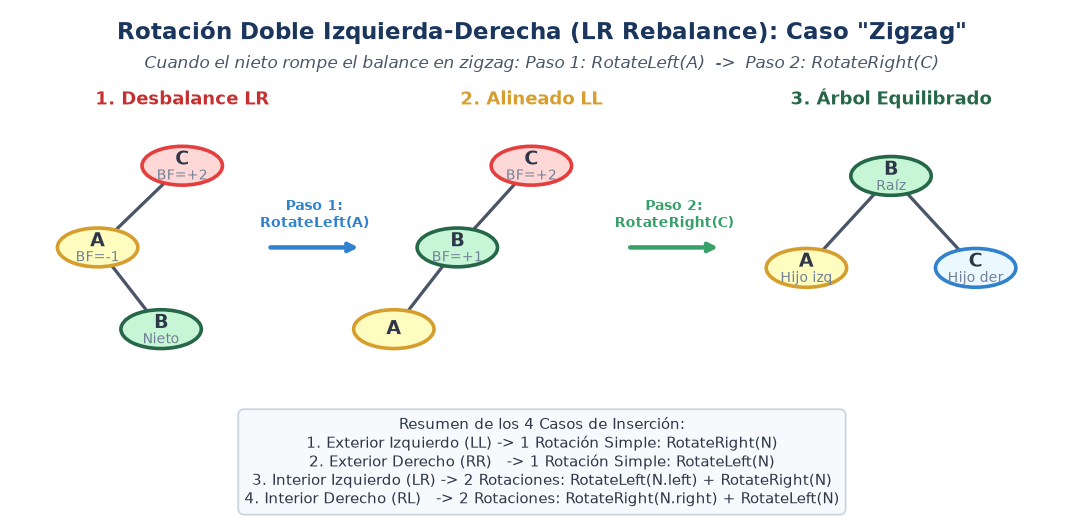
</div>

### 5.3 El Caso Espejo: Rotación Doble Derecha-Izquierda (RL Rebalance)
Simétricamente, si un nodo tiene $BF = -2$ y su hijo derecho tiene $BF = +1$ (forma de zigzag hacia la derecha):
1. **Paso 1:** Aplicamos `RotateRight(N.right)` para alinear el subárbol derecho.
2. **Paso 2:** Aplicamos `RotateLeft(N)` sobre el nodo desbalanceado.


### 5.5 Demostración Interactiva en Java: Rotaciones Dobles (Casos LR y RL)

El siguiente código en Java reproduce exactamente el caso "zigzag" y ejecuta paso a paso la solución en dos etapas demostrando cómo se restaura el equilibrio perfecto.


In [3]:
%%writefile DemostracionRotacionesDobles.java
public class DemostracionRotacionesDobles {

    static class Node {
        int key, height;
        Node left, right;
        public Node(int key) {
            this.key = key;
            this.height = 1;
        }
    }

    static int height(Node n) { return (n == null) ? 0 : n.height; }
    static int getBF(Node n) { return (n == null) ? 0 : height(n.left) - height(n.right); }

    static void updateHeight(Node n) {
        if (n != null) n.height = 1 + Math.max(height(n.left), height(n.right));
    }

    static Node rotateRight(Node y) {
        Node x = y.left;
        Node T2 = x.right;
        x.right = y;
        y.left = T2;
        updateHeight(y);
        updateHeight(x);
        return x;
    }

    static Node rotateLeft(Node x) {
        Node y = x.right;
        Node T2 = y.left;
        y.left = x;
        x.right = T2;
        updateHeight(x);
        updateHeight(y);
        return y;
    }

    static Node rotateLeftRight(Node node) {
        System.out.println("  [LR Paso 1]: RotateLeft sobre hijo izquierdo (" + node.left.key + ")");
        node.left = rotateLeft(node.left);
        System.out.println("  [LR Paso 2]: RotateRight sobre nodo (" + node.key + ")");
        return rotateRight(node);
    }

    static Node rotateRightLeft(Node node) {
        System.out.println("  [RL Paso 1]: RotateRight sobre hijo derecho (" + node.right.key + ")");
        node.right = rotateRight(node.right);
        System.out.println("  [RL Paso 2]: RotateLeft sobre nodo (" + node.key + ")");
        return rotateLeft(node);
    }

    static void printTree(Node node, String prefix, boolean isLeft) {
        if (node != null) {
            System.out.println(prefix + (isLeft ? "|-- (L) " : "\\-- (R) ")
                               + node.key + " [h=" + node.height + ", BF=" + getBF(node) + "]");
            printTree(node.left, prefix + (isLeft ? "|   " : "    "), true);
            printTree(node.right, prefix + (isLeft ? "|   " : "    "), false);
        }
    }

    public static void main(String[] args) {
        System.out.println("======================================================================");
        System.out.println("DEMOSTRACION 1: Rotacion Doble Izquierda-Derecha (Caso LR - Zigzag)");
        System.out.println("======================================================================");
        Node rootLR = new Node(30);
        rootLR.left = new Node(10);
        rootLR.left.right = new Node(20);
        updateHeight(rootLR.left);
        updateHeight(rootLR);

        System.out.println("Arbol inicial (Zigzag: Raiz 30 con BF=+2, Hijo 10 con BF=-1):");
        printTree(rootLR, "", false);

        System.out.println();
        System.out.println("Ejecutando Rotacion Doble LR:");
        rootLR = rotateLeftRight(rootLR);

        System.out.println();
        System.out.println("Arbol resultante (Equilibrio perfecto, raiz es 20):");
        printTree(rootLR, "", false);

        System.out.println();
        System.out.println("======================================================================");
        System.out.println("DEMOSTRACION 2: Rotacion Doble Derecha-Izquierda (Caso RL - Zagzig)");
        System.out.println("======================================================================");
        Node rootRL = new Node(10);
        rootRL.right = new Node(30);
        rootRL.right.left = new Node(20);
        updateHeight(rootRL.right);
        updateHeight(rootRL);

        System.out.println("Arbol inicial (Zagzig: Raiz 10 con BF=-2, Hijo 30 con BF=+1):");
        printTree(rootRL, "", false);

        System.out.println();
        System.out.println("Ejecutando Rotacion Doble RL:");
        rootRL = rotateRightLeft(rootRL);

        System.out.println();
        System.out.println("Arbol resultante (Equilibrio perfecto, raiz es 20):");
        printTree(rootRL, "", false);
    }
}


Writing DemostracionRotacionesDobles.java


In [4]:
!javac -encoding UTF-8 DemostracionRotacionesDobles.java
!java DemostracionRotacionesDobles


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
DEMOSTRACION 1: Rotacion Doble Izquierda-Derecha (Caso LR - Zigzag)
Arbol inicial (Zigzag: Raiz 30 con BF=+2, Hijo 10 con BF=-1):
\-- (R) 30 [h=3, BF=2]
    |-- (L) 10 [h=2, BF=-1]
    |   \-- (R) 20 [h=1, BF=0]

Ejecutando Rotacion Doble LR:
  [LR Paso 1]: RotateLeft sobre hijo izquierdo (10)
  [LR Paso 2]: RotateRight sobre nodo (30)

Arb

## 6. Algoritmo Completo de Inserción en Árboles AVL (`AVLInsert`)

Una vez dominadas las rotaciones, podemos ensamblar el algoritmo completo de inserción.

### 6.1 Mecanismo de Inserción y Propagación
> **Observación Crucial:**
> Al insertar una nueva clave, las alturas de los nodos en el árbol permanecen idénticas **excepto en los nodos situados a lo largo del camino desde el nuevo nodo hasta la raíz**.
> Por tanto, solo necesitamos verificar y actualizar las alturas en dicho camino.

El proceso consta de tres etapas:
1. **Inserción BST estándar:** Se recorre el árbol de arriba hacia abajo comparando la clave hasta encontrar la posición nula e insertar el nuevo nodo hoja ($h = 1$).
2. **Ascenso y Ajuste de Altura (`AdjustHeight`):** En el retorno de la recursión (o subiendo mediante punteros al padre), se recalcula la altura de cada ancestro:
   $$N.\text{Height} = 1 + \max(N.\text{Left}.\text{Height},\; N.\text{Right}.\text{Height})$$
3. **Verificación y Rebalanceo (`Rebalance`):** Si en algún ancestro se detecta $|BF(N)| = 2$, se aplica inmediatamente la rotación correspondiente (LL, RR, LR o RL).

### 6.2 Pseudocódigo Formal de Daniel Kane

```text
Rebalance(N):
    P <- N.Parent
    if N.Left.Height > N.Right.Height + 1:
        RebalanceRight(N)
    if N.Right.Height > N.Left.Height + 1:
        RebalanceLeft(N)
    AdjustHeight(N)
    if P != null:
        Rebalance(P)

RebalanceRight(N):
    M <- N.Left
    if M.Right.Height > M.Left.Height:
        RotateLeft(M)      // Caso LR: rotar hijo primero
    RotateRight(N)         // Luego rotar N
    AdjustHeight en nodos afectados
```

En la implementación recursiva en Java, el retorno de cada llamada actualiza las referencias de los hijos de forma natural y limpia.


### 6.3 Implementación Completa y Ejecutable de un Árbol AVL en Java

A continuación presentamos una clase `AVLTree` industrial y completa en Java, que maneja la inserción de claves, detecta automáticamente los 4 casos de desbalance, ejecuta las rotaciones apropiadas y reporta en consola exactamente qué operación de balanceo tuvo lugar.


In [5]:
%%writefile DemostracionAVLCompleto.java
public class DemostracionAVLCompleto {

    static class Node {
        int key;
        int height;
        Node left, right;

        public Node(int key) {
            this.key = key;
            this.height = 1;
        }
    }

    public static class AVLTree {
        private Node root;

        public int height() {
            return height(root);
        }

        private int height(Node n) {
            return (n == null) ? 0 : n.height;
        }

        private int getBalanceFactor(Node n) {
            return (n == null) ? 0 : height(n.left) - height(n.right);
        }

        private void updateHeight(Node n) {
            if (n != null) {
                n.height = 1 + Math.max(height(n.left), height(n.right));
            }
        }

        private Node rotateRight(Node y) {
            Node x = y.left;
            Node T2 = x.right;

            x.right = y;
            y.left = T2;

            updateHeight(y);
            updateHeight(x);

            return x;
        }

        private Node rotateLeft(Node x) {
            Node y = x.right;
            Node T2 = y.left;

            y.left = x;
            x.right = T2;

            updateHeight(x);
            updateHeight(y);

            return y;
        }

        public void insert(int key) {
            System.out.println();
            System.out.println(">>> Insertando clave: " + key + " ...");
            root = insertRecursive(root, key);
        }

        private Node insertRecursive(Node node, int key) {
            if (node == null) {
                return new Node(key);
            }

            if (key < node.key) {
                node.left = insertRecursive(node.left, key);
            } else if (key > node.key) {
                node.right = insertRecursive(node.right, key);
            } else {
                System.out.println("    [Aviso] Clave duplicada: " + key + " (no insertada).");
                return node;
            }

            updateHeight(node);
            int balance = getBalanceFactor(node);

            // CASO 1: Left-Left (LL)
            if (balance > 1 && key < node.left.key) {
                System.out.println("    [DESBALANCE LL detectado en nodo " + node.key + ", BF=" + balance + "]");
                System.out.println("    -> Aplicando 1 Rotacion Simple: RotateRight(" + node.key + ")");
                return rotateRight(node);
            }

            // CASO 2: Right-Right (RR)
            if (balance < -1 && key > node.right.key) {
                System.out.println("    [DESBALANCE RR detectado en nodo " + node.key + ", BF=" + balance + "]");
                System.out.println("    -> Aplicando 1 Rotacion Simple: RotateLeft(" + node.key + ")");
                return rotateLeft(node);
            }

            // CASO 3: Left-Right (LR)
            if (balance > 1 && key > node.left.key) {
                System.out.println("    [DESBALANCE LR detectado en nodo " + node.key + ", BF=" + balance + "]");
                System.out.println("    -> Aplicando Rotacion Doble LR: RotateLeft(" + node.left.key + ") + RotateRight(" + node.key + ")");
                node.left = rotateLeft(node.left);
                return rotateRight(node);
            }

            // CASO 4: Right-Left (RL)
            if (balance < -1 && key < node.right.key) {
                System.out.println("    [DESBALANCE RL detectado en nodo " + node.key + ", BF=" + balance + "]");
                System.out.println("    -> Aplicando Rotacion Doble RL: RotateRight(" + node.right.key + ") + RotateLeft(" + node.key + ")");
                node.right = rotateRight(node.right);
                return rotateLeft(node);
            }

            return node;
        }

        public boolean contains(int key) {
            Node curr = root;
            while (curr != null) {
                if (key == curr.key) return true;
                curr = (key < curr.key) ? curr.left : curr.right;
            }
            return false;
        }

        public void printTree() {
            if (root == null) {
                System.out.println("    (Arbol vacio)");
                return;
            }
            printSubtree(root, "", false);
        }

        private void printSubtree(Node node, String prefix, boolean isLeft) {
            if (node != null) {
                System.out.println(prefix + (isLeft ? "|-- (L) " : "\\-- (R) ")
                                   + node.key + " [h=" + node.height + ", BF=" + getBalanceFactor(node) + "]");
                printSubtree(node.left, prefix + (isLeft ? "|   " : "    "), true);
                printSubtree(node.right, prefix + (isLeft ? "|   " : "    "), false);
            }
        }

        public void printInOrder() {
            System.out.print("In-Orden: [ ");
            inOrder(root);
            System.out.println("]");
        }

        private void inOrder(Node n) {
            if (n != null) {
                inOrder(n.left);
                System.out.print(n.key + " ");
                inOrder(n.right);
            }
        }
    }

    public static void main(String[] args) {
        AVLTree avl = new AVLTree();

        System.out.println("=======================================================================");
        System.out.println("CONSTRUCCION PROGRESIVA DE UN ARBOL AVL CON ROTACIONES AUTOMATICAS");
        System.out.println("=======================================================================");

        int[] datos = {10, 20, 30, 40, 50, 25};

        for (int x : datos) {
            avl.insert(x);
            System.out.println("Estado del Arbol tras insertar " + x + ":");
            avl.printTree();
            avl.printInOrder();
        }

        System.out.println();
        System.out.println("=======================================================================");
        System.out.println("VERIFICACION DE BUSQUEDA:");
        System.out.println("Contiene 25?: " + avl.contains(25));
        System.out.println("Contiene 99?: " + avl.contains(99));
        System.out.println("Altura total del arbol: " + avl.height());
        System.out.println("=======================================================================");
    }
}


Writing DemostracionAVLCompleto.java


In [6]:
!javac -encoding UTF-8 DemostracionAVLCompleto.java
!java DemostracionAVLCompleto


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
CONSTRUCCION PROGRESIVA DE UN ARBOL AVL CON ROTACIONES AUTOMATICAS

>>> Insertando clave: 10 ...
Estado del Arbol tras insertar 10:
\-- (R) 10 [h=1, BF=0]
In-Orden: [ 10 ]

>>> Insertando clave: 20 ...
Estado del Arbol tras insertar 20:
\-- (R) 10 [h=2, BF=-1]
    \-- (R) 20 [h=1, BF=0]
In-Orden: [ 10 20 ]

>>> Insertando clave: 30 ...
    

## 7. Resolución Pedagógica del Problema de Daniel Kane

> **El Problema de Kane:**
> Dado el siguiente árbol AVL con alturas precalculadas, ¿cuál de las cuatro opciones de inserción candidatas ($A$, $B$, $C$ o $D$) rompería la propiedad AVL, requiriendo que el árbol sea rebalanceado mediante rotaciones?

<div align="center">
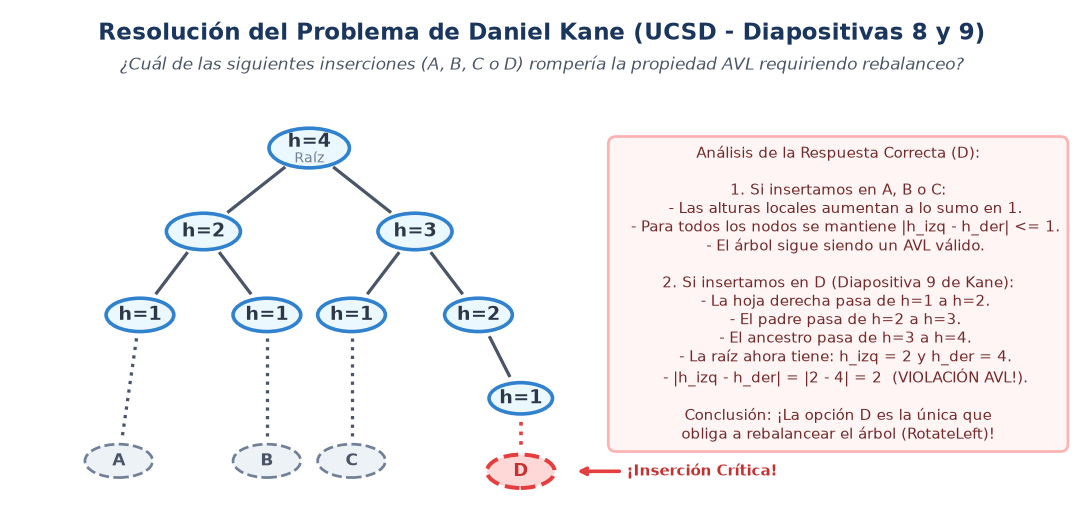
</div>

### Análisis Detallado de Cada Opción de Inserción:

1. **Estado Inicial del Árbol:**
   * **Raíz:** Tiene altura $h = 4$.
   * **Subárbol Izquierdo:** Raíz con altura $h = 2$.
   * **Subárbol Derecho:** Raíz con altura $h = 3$.
   * **Factor de Balance Actual de la Raíz:**
     $$BF(\text{Raíz}) = h_{\text{izq}} - h_{\text{der}} = 2 - 3 = -1 \quad (\text{Válido en AVL})$$

2. **Evaluando la Inserción en $A$ o en $B$:**
   * $A$ y $B$ cuelgan de las hojas del subárbol izquierdo (que actualmente tienen altura 1).
   * Al insertar un nuevo hijo en $A$ o $B$, la hoja pasa a altura 2, y su padre pasa a altura $1 + \max(2, 1) = 3$.
   * La raíz del árbol tendría entonces: $h_{\text{izq}} = 3$ y $h_{\text{der}} = 3$.
   * El nuevo factor de balance de la raíz sería $BF = 3 - 3 = 0$. **¡El árbol queda aún más equilibrado!** No requiere rebalanceo.

3. **Evaluando la Inserción en $C$:**
   * $C$ es hijo izquierdo del nodo derecho con altura 3.
   * Su hermano derecho ya tiene altura 2. Por tanto, aunque la hoja donde cuelga $C$ crezca de altura 1 a 2, la altura del padre se calcula como $1 + \max(2, 2) = 3$.
   * La altura del subárbol derecho **no cambia** (sigue siendo 3). La raíz no sufre ningún cambio de altura. No hay desbalance.

4. **Evaluando la Inserción en $D$ (LA RESPUESTA CORRECTA):**
   * $D$ se inserta debajo de la hoja más profunda del subárbol derecho (la cual tiene altura 1).
   * Dicha hoja pasa a tener altura 2.
   * Su padre (que tenía altura 2) ahora tiene altura $1 + \max(0, 2) = 3$.
   * El ancestro inmediato (que tenía altura 3) ahora tiene hijos de altura 1 y 3 $\implies 1 + \max(1, 3) = 4$.
   * Finalmente, llegamos a la **raíz del árbol global**:
     * Su subárbol izquierdo sigue teniendo altura $h_{\text{izq}} = 2$.
     * Su subárbol derecho ahora creció a altura $h_{\text{der}} = 4$.
     * Calculamos su Factor de Balance:
       $$BF(\text{Raíz}) = 2 - 4 = -2$$
     * **¡$|BF| = 2$ viola la propiedad AVL!**
   * Como se trata de un desbalance causado por una inserción en el subárbol derecho del hijo derecho (camino RR), se requiere obligatoriamente una **rotación simple a la izquierda `RotateLeft`** sobre la raíz para restaurar el balance.


## 8. Análisis Comparativo de Rendimiento (BST Degenerado vs. Árbol AVL)

La siguiente tabla resume el contraste radical entre un Árbol Binario de Búsqueda no balanceado y un Árbol AVL:

| Operación | BST Estándar (Caso Promedio) | BST Estándar (Peor Caso) | Árbol AVL (Caso Promedio) | Árbol AVL (Peor Caso) |
| :--- | :---: | :---: | :---: | :---: |
| **Búsqueda (`contains`)** | $O(\log n)$ | $O(n)$ | $O(\log n)$ | **$O(\log n)$** |
| **Inserción (`insert`)** | $O(\log n)$ | $O(n)$ | $O(\log n)$ | **$O(\log n)$** |
| **Altura Máxima ($h$)** | $\approx 1.39 \log_2 n$ | $n$ | $\approx 1.01 \log_2 n$ | **$\le 1.44 \log_2 n$** |
| **Sobrecosto de Memoria** | Ninguno adicional | Ninguno | 1 entero por nodo (`height`) | 1 entero por nodo |
| **Costo de Rebalanceo** | No aplica | No aplica | $O(1)$ amortizado | A lo sumo 2 rotaciones ($O(1)$) |

### Impacto Práctico:
Para una base de datos con $n = 1{,}000{,}000$ de registros:
* En un **BST degenerado**, una búsqueda en el peor caso requiere **1,000,000 de accesos a memoria**.
* En un **Árbol AVL**, la altura máxima teórica es $1.44 \times \log_2(10^6) \approx 28$ niveles. ¡Una búsqueda en el peor caso requiere **a lo sumo 28 comparaciones**!
* La pequeña inversión de tiempo $O(1)$ al rotar durante la inserción paga dividendos colosales en cada consulta posterior.


## 9. Ejercicios Prácticos

A continuación se presentan 5 ejercicios prácticos progresivos diseñados para afianzar el dominio conceptual y técnico de las rotaciones y la inserción en Árboles AVL. Cada ejercicio cuenta con su contexto, objetivos claros y una plantilla de código lista para completar y ejecutar en Google Colab.


### Ejercicio 1: Implementación de Rotaciones Simples (`RotacionesSimples.java`)
**Objetivo:** Completar manualmente los métodos `rotateRight` y `rotateLeft` asegurando la correcta actualización de las referencias de los nodos y el recálculo de alturas.

**Instrucciones:**
1. En el método `rotateRight(Node y)`, identifique la nueva raíz `x = y.left` y el subárbol central `T2 = x.right`. Reasigne los punteros para que `y` sea el hijo derecho de `x` y `T2` sea el hijo izquierdo de `y`.
2. Actualice las alturas en el orden correcto (`y` primero, luego `x`).
3. Complete de forma simétrica el método `rotateLeft(Node x)`.
4. Ejecute la celda y verifique que las pruebas unitarias pasen exitosamente.


In [ ]:
%%writefile RotacionesSimples.java
public class RotacionesSimples {

    static class Node {
        int key;
        int height;
        Node left, right;
        public Node(int key) {
            this.key = key;
            this.height = 1;
        }
    }

    static int height(Node n) { return (n == null) ? 0 : n.height; }
    static int getBF(Node n) { return (n == null) ? 0 : height(n.left) - height(n.right); }

    static void updateHeight(Node n) {
        if (n != null) n.height = 1 + Math.max(height(n.left), height(n.right));
    }

    // TODO 1: Implemente la rotacion simple a la derecha
    public static Node rotateRight(Node y) {
        // --- ESCRIBA SU CODIGO AQUI ---
        Node x = y.left;
        Node T2 = x.right;

        x.right = y;
        y.left = T2;

        updateHeight(y);
        updateHeight(x);

        return x;
        // ------------------------------
    }

    // TODO 2: Implemente la rotacion simple a la izquierda
    public static Node rotateLeft(Node x) {
        // --- ESCRIBA SU CODIGO AQUI ---
        Node y = x.right;
        Node T2 = y.left;

        y.left = x;
        x.right = T2;

        updateHeight(x);
        updateHeight(y);

        return y;
        // ------------------------------
    }

    public static void main(String[] args) {
        System.out.println("=== TEST EJERCICIO 1: ROTACIONES SIMPLES ===");

        // Test 1: RotateRight
        Node r1 = new Node(30);
        r1.left = new Node(20);
        r1.left.left = new Node(10);
        updateHeight(r1.left);
        updateHeight(r1);

        r1 = rotateRight(r1);
        boolean test1Ok = (r1.key == 20 && r1.left.key == 10 && r1.right.key == 30 && r1.height == 2);
        System.out.println("Prueba RotateRight (Caso LL): " + (test1Ok ? "PASO [OK]" : "FALLO [ERROR]"));

        // Test 2: RotateLeft
        Node r2 = new Node(10);
        r2.right = new Node(20);
        r2.right.right = new Node(30);
        updateHeight(r2.right);
        updateHeight(r2);

        r2 = rotateLeft(r2);
        boolean test2Ok = (r2.key == 20 && r2.left.key == 10 && r2.right.key == 30 && r2.height == 2);
        System.out.println("Prueba RotateLeft (Caso RR):  " + (test2Ok ? "PASO [OK]" : "FALLO [ERROR]"));
    }
}


In [ ]:
!javac -encoding UTF-8 RotacionesSimples.java
!java RotacionesSimples


### Ejercicio 2: Implementación de Rotaciones Dobles LR y RL (`RotacionesDobles.java`)
**Objetivo:** Implementar los métodos de rebalanceo compuesto `rotateLeftRight` (LR) y `rotateRightLeft` (RL) combinando las rotaciones simples correspondientes.

**Instrucciones:**
1. En `rotateLeftRight(Node node)`, aplique primero `rotateLeft` sobre el hijo izquierdo (`node.left`) y asigne el resultado nuevamente a `node.left`. Luego retorne el resultado de aplicar `rotateRight` sobre `node`.
2. En `rotateRightLeft(Node node)`, aplique primero `rotateRight` sobre el hijo derecho (`node.right`) y asigne el resultado a `node.right`. Luego retorne `rotateLeft(node)`.
3. Verifique que ambos casos restauren el factor de balance a 0 y la altura a 2.


In [ ]:
%%writefile RotacionesDobles.java
public class RotacionesDobles {

    static class Node {
        int key, height;
        Node left, right;
        public Node(int key) {
            this.key = key;
            this.height = 1;
        }
    }

    static int height(Node n) { return (n == null) ? 0 : n.height; }
    static int getBF(Node n) { return (n == null) ? 0 : height(n.left) - height(n.right); }

    static void updateHeight(Node n) {
        if (n != null) n.height = 1 + Math.max(height(n.left), height(n.right));
    }

    static Node rotateRight(Node y) {
        Node x = y.left;
        Node T2 = x.right;
        x.right = y;
        y.left = T2;
        updateHeight(y);
        updateHeight(x);
        return x;
    }

    static Node rotateLeft(Node x) {
        Node y = x.right;
        Node T2 = y.left;
        y.left = x;
        x.right = T2;
        updateHeight(x);
        updateHeight(y);
        return y;
    }

    // TODO 1: Implemente la Rotacion Doble Left-Right (LR)
    public static Node rotateLeftRight(Node node) {
        // --- ESCRIBA SU CODIGO AQUI ---
        node.left = rotateLeft(node.left);
        return rotateRight(node);
        // ------------------------------
    }

    // TODO 2: Implemente la Rotacion Doble Right-Left (RL)
    public static Node rotateRightLeft(Node node) {
        // --- ESCRIBA SU CODIGO AQUI ---
        node.right = rotateRight(node.right);
        return rotateLeft(node);
        // ------------------------------
    }

    public static void main(String[] args) {
        System.out.println("=== TEST EJERCICIO 2: ROTACIONES DOBLES ===");

        // Test LR: 30 -> izq: 10 -> der: 20
        Node rLR = new Node(30);
        rLR.left = new Node(10);
        rLR.left.right = new Node(20);
        updateHeight(rLR.left);
        updateHeight(rLR);

        rLR = rotateLeftRight(rLR);
        boolean lrOk = (rLR.key == 20 && rLR.left.key == 10 && rLR.right.key == 30 && rLR.height == 2);
        System.out.println("Prueba Rotacion Doble LR: " + (lrOk ? "PASO [OK]" : "FALLO [ERROR]"));

        // Test RL: 10 -> der: 30 -> izq: 20
        Node rRL = new Node(10);
        rRL.right = new Node(30);
        rRL.right.left = new Node(20);
        updateHeight(rRL.right);
        updateHeight(rRL);

        rRL = rotateRightLeft(rRL);
        boolean rlOk = (rRL.key == 20 && rRL.left.key == 10 && rRL.right.key == 30 && rRL.height == 2);
        System.out.println("Prueba Rotacion Doble RL: " + (rlOk ? "PASO [OK]" : "FALLO [ERROR]"));
    }
}


In [ ]:
!javac -encoding UTF-8 RotacionesDobles.java
!java RotacionesDobles


### Ejercicio 3: Inserción Completa en un Árbol AVL (`AVLInsertEjercicio.java`)
**Objetivo:** Completar el método recursivo de inserción en un árbol AVL, integrando la actualización de alturas y la selección condicional de los 4 casos de rebalanceo (LL, RR, LR, RL).

**Instrucciones:**
1. Examine el esqueleto de la clase `AVLTree`.
2. En el método `insertRecursive`, complete las cuatro condiciones condicionales `if` para detectar:
   - Caso LL: `balance > 1 && key < node.left.key`
   - Caso RR: `balance < -1 && key > node.right.key`
   - Caso LR: `balance > 1 && key > node.left.key`
   - Caso RL: `balance < -1 && key < node.right.key`
3. Invoque la rotación correspondiente en cada caso y retorne la nueva raíz.
4. El programa validará que un árbol construido con 15 elementos aleatorios satisfaga estrictamente la propiedad AVL en todos sus nodos.


In [ ]:
%%writefile AVLInsertEjercicio.java
public class AVLInsertEjercicio {

    static class Node {
        int key, height;
        Node left, right;
        public Node(int key) {
            this.key = key;
            this.height = 1;
        }
    }

    static int height(Node n) { return (n == null) ? 0 : n.height; }
    static int getBF(Node n) { return (n == null) ? 0 : height(n.left) - height(n.right); }

    static void updateHeight(Node n) {
        if (n != null) n.height = 1 + Math.max(height(n.left), height(n.right));
    }

    static Node rotateRight(Node y) {
        Node x = y.left;
        Node T2 = x.right;
        x.right = y;
        y.left = T2;
        updateHeight(y);
        updateHeight(x);
        return x;
    }

    static Node rotateLeft(Node x) {
        Node y = x.right;
        Node T2 = y.left;
        y.left = x;
        x.right = T2;
        updateHeight(x);
        updateHeight(y);
        return y;
    }

    public static Node insert(Node node, int key) {
        if (node == null) return new Node(key);

        if (key < node.key) {
            node.left = insert(node.left, key);
        } else if (key > node.key) {
            node.right = insert(node.right, key);
        } else {
            return node;
        }

        updateHeight(node);
        int balance = getBF(node);

        // TODO: Complete los 4 casos de desbalanceo
        // --- ESCRIBA SU CODIGO AQUI ---
        // 1. Caso LL
        if (balance > 1 && key < node.left.key) {
            return rotateRight(node);
        }

        // 2. Caso RR
        if (balance < -1 && key > node.right.key) {
            return rotateLeft(node);
        }

        // 3. Caso LR
        if (balance > 1 && key > node.left.key) {
            node.left = rotateLeft(node.left);
            return rotateRight(node);
        }

        // 4. Caso RL
        if (balance < -1 && key < node.right.key) {
            node.right = rotateRight(node.right);
            return rotateLeft(node);
        }
        // ------------------------------

        return node;
    }

    static boolean isAVL(Node node) {
        if (node == null) return true;
        int bf = getBF(node);
        if (Math.abs(bf) > 1) return false;
        return isAVL(node.left) && isAVL(node.right);
    }

    public static void main(String[] args) {
        System.out.println("=== TEST EJERCICIO 3: INSERCION COMPLETA EN AVL ===");
        Node root = null;
        int[] datos = {50, 20, 60, 10, 30, 25, 28, 70, 80, 75, 5, 15, 22, 27, 90};

        for (int x : datos) {
            root = insert(root, x);
        }

        boolean avlValido = isAVL(root);
        System.out.println("El arbol satisface la propiedad AVL en todos los nodos?: "
                           + (avlValido ? "SI [PASS]" : "NO [FAIL]"));
        System.out.println("Altura total con 15 nodos: " + height(root) + " (Optimo teorico: 4)");
    }
}


In [ ]:
!javac -encoding UTF-8 AVLInsertEjercicio.java
!java AVLInsertEjercicio


### Ejercicio 4: Instrumentación y Conteo de Rotaciones (`ConteoRotacionesAVL.java`)
**Objetivo:** Instrumentar el árbol AVL con contadores estáticos para registrar cuántas rotaciones simples (LL, RR) y dobles (LR, RL) ocurren al insertar una secuencia estrictamente ordenada `[1, 2, 3, ..., 15]` frente a una secuencia alternada.

**Pregunta de reflexión:**
Al insertar números ordenados secuencialmente de 1 a 15, ¿qué tipo de rotación ocurre exclusivamente? ¿Por qué nunca ocurre una rotación doble en este escenario?


In [ ]:
%%writefile ConteoRotacionesAVL.java
public class ConteoRotacionesAVL {

    static int countLL = 0;
    static int countRR = 0;
    static int countLR = 0;
    static int countRL = 0;

    static class Node {
        int key, height;
        Node left, right;
        public Node(int key) {
            this.key = key;
            this.height = 1;
        }
    }

    static int height(Node n) { return (n == null) ? 0 : n.height; }
    static int getBF(Node n) { return (n == null) ? 0 : height(n.left) - height(n.right); }

    static void updateHeight(Node n) {
        if (n != null) n.height = 1 + Math.max(height(n.left), height(n.right));
    }

    static Node rotateRight(Node y) {
        Node x = y.left;
        Node T2 = x.right;
        x.right = y;
        y.left = T2;
        updateHeight(y);
        updateHeight(x);
        return x;
    }

    static Node rotateLeft(Node x) {
        Node y = x.right;
        Node T2 = y.left;
        y.left = x;
        x.right = T2;
        updateHeight(x);
        updateHeight(y);
        return y;
    }

    public static Node insert(Node node, int key) {
        if (node == null) return new Node(key);

        if (key < node.key) {
            node.left = insert(node.left, key);
        } else if (key > node.key) {
            node.right = insert(node.right, key);
        } else {
            return node;
        }

        updateHeight(node);
        int balance = getBF(node);

        // TODO: Incremente los contadores segun el tipo de rotacion aplicada
        // --- ESCRIBA SU CODIGO AQUI ---
        if (balance > 1 && key < node.left.key) {
            countLL++;
            return rotateRight(node);
        }
        if (balance < -1 && key > node.right.key) {
            countRR++;
            return rotateLeft(node);
        }
        if (balance > 1 && key > node.left.key) {
            countLR++;
            node.left = rotateLeft(node.left);
            return rotateRight(node);
        }
        if (balance < -1 && key < node.right.key) {
            countRL++;
            node.right = rotateRight(node.right);
            return rotateLeft(node);
        }
        // ------------------------------

        return node;
    }

    public static void main(String[] args) {
        System.out.println("=== EXPERIMENTO DE INSTRUMENTACION: CONTEO DE ROTACIONES ===");

        Node root = null;
        System.out.println("Insertando claves en orden ascendente: 1 al 15...");
        for (int i = 1; i <= 15; i++) {
            root = insert(root, i);
        }

        System.out.println();
        System.out.println("Resultados de las Rotaciones:");
        System.out.println(" - Rotaciones Simples LL (RotateRight): " + countLL);
        System.out.println(" - Rotaciones Simples RR (RotateLeft):  " + countRR);
        System.out.println(" - Rotaciones Dobles LR:                " + countLR);
        System.out.println(" - Rotaciones Dobles RL:                " + countRL);
        System.out.println("Total Rotaciones: " + (countLL + countRR + countLR + countRL));
        System.out.println("Altura final del arbol: " + height(root) + " (Sin balance seria 15!)");
    }
}


In [ ]:
!javac -encoding UTF-8 ConteoRotacionesAVL.java
!java ConteoRotacionesAVL


### Ejercicio 5: Aplicación Práctica: Diccionario Simbólico Balanceado (`DiccionarioAVL.java`)
**Objetivo:** Desarrollar un Diccionario / Mapa genérico balanceado `DiccionarioAVL<K extends Comparable<K>, V>` que almacene pares clave-valor (ej. identificadores de variables de un compilador y su tipo de dato), garantizando tiempo de búsqueda $O(\log n)$.

**Instrucciones:**
1. Observe cómo la condición `Comparable<K>` permite utilizar el método `.compareTo()` para guiar las bifurcaciones y detectar las rotaciones.
2. Complete el método `put(K key, V val)` asegurando que si la clave ya existe, su valor se actualice.
3. Ejecute el programa y compruebe la inserción y consulta de símbolos.


In [ ]:
%%writefile DiccionarioAVL.java
public class DiccionarioAVL<K extends Comparable<K>, V> {

    private class EntryNode {
        K key;
        V value;
        int height;
        EntryNode left, right;

        EntryNode(K key, V value) {
            this.key = key;
            this.value = value;
            this.height = 1;
        }
    }

    private EntryNode root;
    private int size = 0;

    private int height(EntryNode n) { return (n == null) ? 0 : n.height; }
    private int getBF(EntryNode n) { return (n == null) ? 0 : height(n.left) - height(n.right); }

    private void updateHeight(EntryNode n) {
        if (n != null) n.height = 1 + Math.max(height(n.left), height(n.right));
    }

    private EntryNode rotateRight(EntryNode y) {
        EntryNode x = y.left;
        EntryNode T2 = x.right;
        x.right = y;
        y.left = T2;
        updateHeight(y);
        updateHeight(x);
        return x;
    }

    private EntryNode rotateLeft(EntryNode x) {
        EntryNode y = x.right;
        EntryNode T2 = y.left;
        y.left = x;
        x.right = T2;
        updateHeight(x);
        updateHeight(y);
        return y;
    }

    public void put(K key, V value) {
        root = putRecursive(root, key, value);
    }

    private EntryNode putRecursive(EntryNode node, K key, V value) {
        if (node == null) {
            size++;
            return new EntryNode(key, value);
        }

        int cmp = key.compareTo(node.key);
        if (cmp < 0) {
            node.left = putRecursive(node.left, key, value);
        } else if (cmp > 0) {
            node.right = putRecursive(node.right, key, value);
        } else {
            node.value = value;
            return node;
        }

        updateHeight(node);
        int balance = getBF(node);

        if (balance > 1 && key.compareTo(node.left.key) < 0) {
            return rotateRight(node);
        }
        if (balance < -1 && key.compareTo(node.right.key) > 0) {
            return rotateLeft(node);
        }
        if (balance > 1 && key.compareTo(node.left.key) > 0) {
            node.left = rotateLeft(node.left);
            return rotateRight(node);
        }
        if (balance < -1 && key.compareTo(node.right.key) < 0) {
            node.right = rotateRight(node.right);
            return rotateLeft(node);
        }

        return node;
    }

    public V get(K key) {
        EntryNode curr = root;
        while (curr != null) {
            int cmp = key.compareTo(curr.key);
            if (cmp == 0) return curr.value;
            curr = (cmp < 0) ? curr.left : curr.right;
        }
        return null;
    }

    public int size() { return size; }
    public int height() { return height(root); }

    public static void main(String[] args) {
        System.out.println("=== TABLA DE SIMBOLOS CON DICCIONARIO AVL ===");
        DiccionarioAVL<String, String> tablaSimbolos = new DiccionarioAVL<>();

        tablaSimbolos.put("contador", "int");
        tablaSimbolos.put("promedio", "double");
        tablaSimbolos.put("activo", "boolean");
        tablaSimbolos.put("nombre", "String");
        tablaSimbolos.put("edad", "int");
        tablaSimbolos.put("salario", "double");
        tablaSimbolos.put("cedula", "String");

        System.out.println("Total simbolos registrados: " + tablaSimbolos.size());
        System.out.println("Altura del arbol AVL: " + tablaSimbolos.height() + " (Balance optimo)");

        System.out.println();
        System.out.println("Consultas rapidas O(log n):");
        System.out.println(" - Tipo de 'contador': " + tablaSimbolos.get("contador"));
        System.out.println(" - Tipo de 'promedio': " + tablaSimbolos.get("promedio"));
        System.out.println(" - Tipo de 'activo':   " + tablaSimbolos.get("activo"));
        System.out.println(" - Tipo de 'inexistente': " + tablaSimbolos.get("inexistente"));
    }
}


In [ ]:
!javac -encoding UTF-8 DiccionarioAVL.java
!java DiccionarioAVL


## 10. Bibliografía y Referencias

1. **Kane, Daniel.** *Data Structures and Algorithms: Binary Search Trees: Balance*. Department of Computer Science and Engineering, University of California, San Diego (UCSD).
2. **Kane, Daniel.** *Data Structures and Algorithms: Binary Search Trees: AVL Trees*. Department of Computer Science and Engineering, University of California, San Diego (UCSD).
3. **Kane, Daniel.** *Data Structures and Algorithms: Binary Search Trees: AVL Tree Implementation*. Department of Computer Science and Engineering, University of California, San Diego (UCSD).
4. **Adelson-Velsky, G. M., & Landis, E. M.** (1962). *An algorithm for the organization of information*. Proceedings of the USSR Academy of Sciences, 146: 263–266.
5. **Streib, J. T., & Soma, T.** (2017). *Guide to Data Structures: A Concise Introduction Using Java*. Springer International Publishing.
6. **Cormen, T. H., Leiserson, C. E., Rivest, R. L., & Stein, C.** (2022). *Introduction to Algorithms* (4th ed.). MIT Press.
7. **Sedgewick, R., & Wayne, K.** (2011). *Algorithms* (4th ed.). Addison-Wesley Professional.
8. **Galles, David.** *AVL Tree Visualization Tool*. University of San Francisco (USFCA): [https://www.cs.usfca.edu/~galles/visualization/AVLtree.html](https://www.cs.usfca.edu/~galles/visualization/AVLtree.html).
